In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%%writefile -a /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


# ================= Phase 5: Edge metrics =================
def count_macs(model, in_ch=3, T=FRAMES, R=32):
    """Multiply-accumulate operations for one inference (Conv2d + Linear)."""
    macs = 0

    def conv_hook(m, inp, out):
        nonlocal macs
        k = m.kernel_size[0] * m.kernel_size[1] * (m.in_channels // m.groups)
        macs += out.numel() // out.shape[0] * k

    def lin_hook(m, inp, out):
        nonlocal macs
        macs += m.in_features * m.out_features

    hooks = []
    for mod in model.modules():
        if isinstance(mod, nn.Conv2d):
            hooks.append(mod.register_forward_hook(conv_hook))
        elif isinstance(mod, nn.Linear):
            hooks.append(mod.register_forward_hook(lin_hook))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, in_ch, T, R))
    for h in hooks:
        h.remove()
    return macs

Appending to /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


In [3]:
import sys, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, '/content/drive/MyDrive/RadarGestureEdgeAI')
import radar_utils as ru
importlib.reload(ru)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)

Xc, y, meta = ru.load_compact()
print("Xc:", Xc.shape)
print("Check M model MACs:", f"{ru.count_macs(ru.TinyRadarCNN()):,}")

Device: cuda
Xc: (9593, 90, 32, 3)
Check M model MACs: 7,806,720


XS: training...
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_width_XS.csv
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_width_XS_predictions.csv
[width_XS] mean F1 = 78.4 | worst = 70.2 | 2.4 min
S : training...
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_width_S.csv
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_width_S_predictions.csv
[width_S] mean F1 = 88.5 | worst = 82.8 | 2.4 min
M : loaded from Drive
L : training...
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_width_L.csv
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_width_L_predictions.csv
[width_L] mean F1 = 90.7 | worst = 82.6 | 4.7 min

===== MODEL SIZE SWEEP (LOSO, 3 radars) =====
size        widths  params  int8_KB  MACs_M  mean_F1  std_F1  worst_F1
  XS    (4, 8, 16)    1808      1.8    0.72     78.4     5.4      70.2
   S   (8, 16, 32)    6484      6.3    2.26     88.5     4.9      82.8
   M  (16, 32, 64)   24476     23.9  

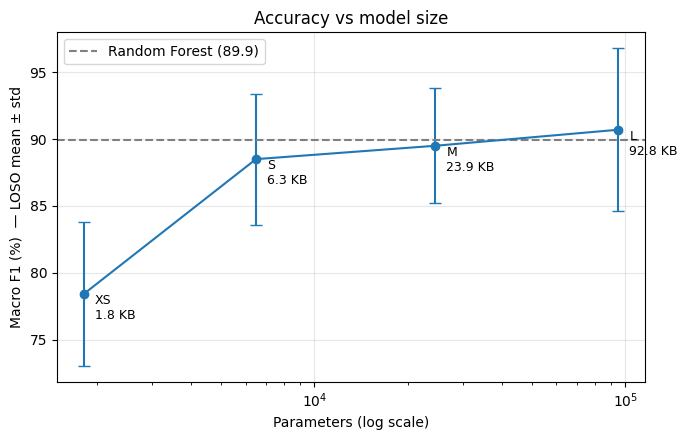

In [4]:
sizes = {
    'XS': (4, 8, 16),
    'S':  (8, 16, 32),
    'M':  (16, 32, 64),
    'L':  (32, 64, 128),
}

sweep = {}
for name, w in sizes.items():
    tag = 'sensor_LTR' if name == 'M' else f'width_{name}'   # M already trained in Phase 4
    path = ru.PROJECT / 'results' / f'loso_{tag}.csv'
    if path.exists():
        sweep[name] = pd.read_csv(path)
        print(f"{name:2s}: loaded from Drive")
    else:
        print(f"{name:2s}: training...")
        sweep[name] = ru.run_cnn_loso(Xc, y, meta, DEVICE, tag=tag,
                                      widths=w, verbose=False)

rows = []
for name, w in sizes.items():
    model = ru.TinyRadarCNN(widths=w)
    params = ru.count_params(model)
    d = sweep[name]
    rows.append({'size': name, 'widths': str(w), 'params': params,
                 'int8_KB': round(params / 1024, 1),
                 'MACs_M': round(ru.count_macs(model) / 1e6, 2),
                 'mean_F1': round(d.macro_f1.mean() * 100, 1),
                 'std_F1': round(d.macro_f1.std() * 100, 1),
                 'worst_F1': round(d.macro_f1.min() * 100, 1)})
tab = pd.DataFrame(rows)
print("\n===== MODEL SIZE SWEEP (LOSO, 3 radars) =====")
print(tab.to_string(index=False))
ru.save_results(tab, 'table_size_sweep')

# Pareto plot: accuracy vs model size
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(tab.params, tab.mean_F1, yerr=tab.std_F1, fmt='o-', capsize=4)
for _, r in tab.iterrows():
    ax.annotate(f"{r['size']}\n{r['int8_KB']} KB", (r.params, r.mean_F1),
                textcoords='offset points', xytext=(8, -18), fontsize=9)
ax.axhline(89.9, ls='--', color='gray', label='Random Forest (89.9)')
ax.set_xscale('log')
ax.set_xlabel('Parameters (log scale)')
ax.set_ylabel('Macro F1 (%)  — LOSO mean ± std')
ax.set_title('Accuracy vs model size')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(ru.PROJECT / 'figures' / 'fig_size_pareto.png', dpi=200)
plt.show()

In [5]:
final = {'M': (16, 32, 64), 'S': (8, 16, 32)}

for name, w in final.items():
    tag = f'final_{name}'
    have = all((ru.PROJECT / 'models' / f'{tag}_fold{k}.pt').exists() for k in range(1, 9))
    if have:
        print(f"{tag}: models already on Drive")
    else:
        print(f"{tag}: training + saving 8 fold models...")
        ru.run_cnn_loso(Xc, y, meta, DEVICE, tag=tag, widths=w,
                        save_models=True, verbose=False)

final_M: training + saving 8 fold models...
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_final_M.csv
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_final_M_predictions.csv
[final_M] mean F1 = 89.6 | worst = 84.0 | 3.2 min
final_S: training + saving 8 fold models...
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_final_S.csv
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_final_S_predictions.csv
[final_S] mean F1 = 88.4 | worst = 81.3 | 2.4 min


In [6]:
%%writefile -a /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


# ================= Phase 5.2: INT8 deployment (PyTorch -> TFLite) =================
def load_fold_model(tag, fold_k, widths=(16, 32, 64), in_ch=3):
    """Load a saved LOSO fold model + its input normalisation stats."""
    ck = torch.load(PROJECT / 'models' / f'{tag}_fold{fold_k}.pt',
                    map_location='cpu', weights_only=False)
    model = TinyRadarCNN(in_ch=in_ch, widths=widths)
    model.load_state_dict(ck['state_dict'])
    model.eval()
    return model, np.asarray(ck['mean'], np.float32), np.asarray(ck['std'], np.float32)


def normalize_input(Xc, idx, mean, std, channels=(0, 1, 2)):
    """Same input pipeline as training -> (N, 90, 32, C) float32 (NHWC)."""
    return ((prepare_input(Xc, idx, 'persample', channels) - mean) / std).astype(np.float32)


def fold_bn(model):
    """Fold every BatchNorm into the conv before it (standard MCU deployment step)."""
    layers = [m for m in model.modules()
              if isinstance(m, (nn.Conv2d, nn.BatchNorm2d, nn.Linear))]
    convs = []
    with torch.no_grad():
        for conv, bn in zip(layers[0:-1:2], layers[1:-1:2]):
            s = bn.weight / torch.sqrt(bn.running_var + bn.eps)
            w = conv.weight * s[:, None, None, None]
            b = bn.bias - bn.running_mean * s
            convs.append((w.permute(2, 3, 1, 0).numpy().copy(), b.numpy().copy()))  # OIHW -> HWIO
        lin = layers[-1]
        dense = (lin.weight.T.numpy().copy(), lin.bias.numpy().copy())
    return convs, dense


def build_tf_model(model):
    """Re-create the trained TinyRadarCNN as a TensorFlow graph (NHWC, BN folded)."""
    import tensorflow as tf
    convs, (wd, bd) = fold_bn(model)

    class TFRadarCNN(tf.Module):
        def __init__(self):
            super().__init__()
            self.w = [tf.Variable(w, trainable=False) for w, _ in convs]
            self.b = [tf.Variable(b, trainable=False) for _, b in convs]
            self.wd = tf.Variable(wd, trainable=False)
            self.bd = tf.Variable(bd, trainable=False)

        @tf.function
        def __call__(self, x):
            for i in range(len(self.w)):
                x = tf.nn.relu(tf.nn.conv2d(x, self.w[i], 1, 'SAME') + self.b[i])
                if i < len(self.w) - 1:                      # blocks 1, 2 have MaxPool
                    x = tf.nn.max_pool2d(x, 2, 2, 'VALID')
            x = tf.reduce_mean(x, axis=[1, 2])               # global average pool
            return tf.matmul(x, self.wd) + self.bd

    return TFRadarCNN()


def convert_tflite(tf_model, rep_x=None, out_path=None):
    """TFLite export. rep_x given -> full INT8 (weights + activations + I/O), else float32."""
    import tensorflow as tf
    spec = tf.TensorSpec([1, *rep_x.shape[1:]] if rep_x is not None
                         else [1, FRAMES, 32, tf_model.w[0].shape[2]], tf.float32)
    cf = tf_model.__call__.get_concrete_function(spec)
    conv = tf.lite.TFLiteConverter.from_concrete_functions([cf], tf_model)
    if rep_x is not None:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = lambda: ([rep_x[i:i + 1]] for i in range(len(rep_x)))
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conv.inference_input_type = tf.int8
        conv.inference_output_type = tf.int8
    tfl = conv.convert()
    if out_path is not None:
        Path(out_path).write_bytes(tfl)
    return tfl


def tflite_predict(tfl, x):
    """Run a .tflite model sample-by-sample (like a microcontroller would)."""
    try:
        from ai_edge_litert.interpreter import Interpreter
    except ImportError:
        import tensorflow as tf
        Interpreter = tf.lite.Interpreter
    it = Interpreter(model_content=tfl)
    it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    preds = np.empty(len(x), dtype=np.int64)
    for i in range(len(x)):
        xi = x[i:i + 1]
        if inp['dtype'] == np.int8:
            s, z = inp['quantization']
            xi = np.clip(np.round(xi / s + z), -128, 127).astype(np.int8)
        it.set_tensor(inp['index'], xi)
        it.invoke()
        preds[i] = it.get_tensor(out['index'])[0].argmax()
    return preds

Appending to /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


In [7]:
import warnings, subprocess
warnings.filterwarnings('ignore')
try:
    import tensorflow as tf
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow'], check=True)
    import tensorflow as tf
try:
    tf.config.set_visible_devices([], 'GPU')   # TF on CPU, GPU stays free for PyTorch
except RuntimeError:
    pass
print("TensorFlow:", tf.__version__)
importlib.reload(ru)

final = {'M': (16, 32, 64), 'S': (8, 16, 32)}
rows = []
for name, w in final.items():
    tag = f'final_{name}'
    for fold in ru.loso_folds(meta):
        k, te = fold['fold'], fold['test_idx']
        model, mu, sd = ru.load_fold_model(tag, k, widths=w)
        x_te = ru.normalize_input(Xc, te, mu, sd)

        # 1) original PyTorch float32
        with torch.no_grad():
            p_torch = model(torch.from_numpy(np.ascontiguousarray(
                x_te.transpose(0, 3, 1, 2)))).argmax(1).numpy()

        # 2) TFLite float32 and 3) TFLite INT8 (calibration = 500 TRAIN-subject samples only)
        tfm = ru.build_tf_model(model)
        rep_idx = np.random.default_rng(k).choice(fold['train_idx'], 500, replace=False)
        rep = ru.normalize_input(Xc, rep_idx, mu, sd)
        f32 = ru.convert_tflite(tfm)
        i8 = ru.convert_tflite(tfm, rep, ru.PROJECT / 'models' / f'{tag}_fold{k}_int8.tflite')
        p_f32 = ru.tflite_predict(f32, x_te)
        p_i8 = ru.tflite_predict(i8, x_te)

        f1 = lambda p: ru.evaluate(y[te], p)['macro_f1'] * 100
        rows.append({'size': name, 'fold': k, 'test_subject': fold['test_subject'],
                     'F1_torch': f1(p_torch), 'F1_tflite_f32': f1(p_f32), 'F1_int8': f1(p_i8),
                     'agree_int8_pct': (p_i8 == p_torch).mean() * 100,
                     'f32_KB': len(f32) / 1024, 'int8_KB': len(i8) / 1024})
        r = rows[-1]
        print(f"{name} fold {k} (S{r['test_subject']}): torch {r['F1_torch']:.1f} | "
              f"tflite-f32 {r['F1_tflite_f32']:.1f} | INT8 {r['F1_int8']:.1f} | "
              f"agree {r['agree_int8_pct']:.1f}%")

df = pd.DataFrame(rows).round(2)
ru.save_results(df, 'int8_per_fold')

summ = df.groupby('size', sort=False).agg(
    F1_float=('F1_torch', 'mean'), F1_int8=('F1_int8', 'mean'),
    std_int8=('F1_int8', 'std'), worst_int8=('F1_int8', 'min'),
    agree_pct=('agree_int8_pct', 'mean'),
    f32_KB=('f32_KB', 'first'), int8_KB=('int8_KB', 'first')).round(1)
summ['drop'] = (summ.F1_int8 - summ.F1_float).round(2)
summ['compression'] = (summ.f32_KB / summ.int8_KB).round(1).astype(str) + 'x'
print("\n===== INT8 QUANTIZATION (LOSO, full-integer TFLite) =====")
print(summ.to_string())
ru.save_results(summ.reset_index(), 'table_int8_quantization')

TensorFlow: 2.21.0
M fold 1 (S1): torch 93.1 | tflite-f32 93.1 | INT8 91.8 | agree 97.9%
M fold 2 (S2): torch 86.4 | tflite-f32 86.4 | INT8 85.9 | agree 97.6%
M fold 3 (S3): torch 84.0 | tflite-f32 84.0 | INT8 84.3 | agree 97.0%
M fold 4 (S4): torch 85.8 | tflite-f32 85.8 | INT8 85.6 | agree 97.6%
M fold 5 (S5): torch 90.7 | tflite-f32 90.7 | INT8 90.8 | agree 99.1%
M fold 6 (S6): torch 87.6 | tflite-f32 87.6 | INT8 87.6 | agree 96.2%
M fold 7 (S7): torch 95.6 | tflite-f32 95.6 | INT8 95.4 | agree 99.4%
M fold 8 (S8): torch 93.2 | tflite-f32 93.2 | INT8 93.0 | agree 98.3%
S fold 1 (S1): torch 94.4 | tflite-f32 94.4 | INT8 93.9 | agree 98.2%
S fold 2 (S2): torch 85.1 | tflite-f32 85.1 | INT8 86.7 | agree 93.3%
S fold 3 (S3): torch 81.3 | tflite-f32 81.3 | INT8 82.0 | agree 97.9%
S fold 4 (S4): torch 83.4 | tflite-f32 83.4 | INT8 82.8 | agree 97.2%
S fold 5 (S5): torch 89.0 | tflite-f32 89.0 | INT8 89.3 | agree 97.5%
S fold 6 (S6): torch 86.9 | tflite-f32 86.9 | INT8 87.0 | agree 98.2%
S

In [9]:
import warnings; warnings.filterwarnings('ignore')
import tensorflow as tf
final = {'M': (16, 32, 64), 'S': (8, 16, 32)}

def tflite_memory(tfl):
    """Peak activation RAM (bytes) of an INT8 .tflite model, op by op."""
    try:
        from ai_edge_litert.interpreter import Interpreter
    except ImportError:
        Interpreter = tf.lite.Interpreter
    it = Interpreter(model_content=tfl)
    it.allocate_tensors()
    T = {t['index']: t for t in it.get_tensor_details()}
    ops = [op for op in it._get_ops_details() if op['op_name'] != 'DELEGATE']
    nb = lambda i: int(np.prod(T[i]['shape'])) * np.dtype(T[i]['dtype']).itemsize
    act = {it.get_input_details()[0]['index']} | {o for op in ops for o in op['outputs']}
    per_op = []
    for op in ops:
        mem = sum(nb(i) for i in op['inputs'] if i in act) + sum(nb(o) for o in op['outputs'])
        per_op.append({'op': op['op_name'],
                       'output_shape': 'x'.join(str(int(s)) for s in T[op['outputs'][0]]['shape'][1:]),
                       'live_KB': round(mem / 1024, 1)})
    return pd.DataFrame(per_op)

# ---- streaming pre-processing on the MCU (per frame, causal) ----
C = 3
pre_state_KB = 2 * ru.BINS * C * 4 / 1024     # loop-back background + current frame (float32)
window_KB = ru.FRAMES * 32 * C * 4 / 1024      # compact 90x32x3 window buffer (float32)
pre_MFLOP = 2 * 5 * 256 * np.log2(256) * C * ru.FRAMES / 1e6   # Hilbert = FFT+IFFT (N=256)
RUNTIME_KB = 50                                # approx. TFLite-Micro runtime + app code (flash)

mcus = [  # name, core, MHz, SRAM KB, flash KB, ASSUMED int8 MACs/cycle (CMSIS-NN)
    ('RP2040',    'Cortex-M0+', 133,  264, 2048, 0.1),
    ('nRF52840',  'Cortex-M4F',  64,  256, 1024, 0.4),
    ('STM32L476', 'Cortex-M4F',  80,  128, 1024, 0.4),
    ('STM32H743', 'Cortex-M7',  480, 1024, 2048, 0.8),
]

summary, deploy = [], []
for name, w in final.items():
    tfl = (ru.PROJECT / 'models' / f'final_{name}_fold1_int8.tflite').read_bytes()
    mem = tflite_memory(tfl)
    if name == 'M':
        print("===== Activation memory per layer (model M, INT8) =====")
        print(mem.to_string(index=False), "\n")
    macs = ru.count_macs(ru.TinyRadarCNN(widths=w))
    arena_KB = mem.live_KB.max()
    ram_KB = arena_KB + window_KB + pre_state_KB
    flash_KB = len(tfl) / 1024 + RUNTIME_KB
    summary.append({'model': name, 'MACs_M': round(macs / 1e6, 2),
                    'model_flash_KB': round(len(tfl) / 1024, 1),
                    'arena_KB': arena_KB, 'window_KB': round(window_KB, 1),
                    'preproc_state_KB': round(pre_state_KB, 1),
                    'total_RAM_KB': round(ram_KB, 1), 'total_flash_KB': round(flash_KB, 1)})
    for mcu, core, mhz, sram, flash, eff in mcus:
        deploy.append({'model': name, 'MCU': mcu, 'core': core, 'MHz': mhz,
                       'latency_ms': round(macs / (eff * mhz * 1e6) * 1000, 1),
                       'RAM_use_%': round(100 * ram_KB / sram, 1),
                       'fits': 'YES' if ram_KB <= sram and flash_KB <= flash else 'NO'})

summary, deploy = pd.DataFrame(summary), pd.DataFrame(deploy)
print("===== MEMORY BUDGET (per inference, INT8) =====")
print(summary.to_string(index=False))
print(f"\nPre-processing: ~{pre_MFLOP:.1f} MFLOP per gesture, spread over {ru.FRAMES} frames "
      f"(~{pre_MFLOP * 1e3 / ru.FRAMES:.0f} KFLOP per frame, done while the gesture is recorded)")
print("\n===== ESTIMATED MCU DEPLOYMENT (analytical, to be validated) =====")
print(deploy.to_string(index=False))
ru.save_results(summary, 'table_memory_budget')
ru.save_results(deploy, 'table_mcu_estimates')

===== Activation memory per layer (model M, INT8) =====
             op output_shape  live_KB
        CONV_2D     90x32x16     53.4
    MAX_POOL_2D     45x16x16     56.2
        CONV_2D     45x16x32     33.8
    MAX_POOL_2D      22x8x32     28.0
        CONV_2D      22x8x64     16.5
           MEAN           64     11.1
FULLY_CONNECTED           12      0.1 

===== MEMORY BUDGET (per inference, INT8) =====
model  MACs_M  model_flash_KB  arena_KB  window_KB  preproc_state_KB  total_RAM_KB  total_flash_KB
    M    7.81            30.1      56.2       33.8               4.4          94.4            80.1
    S    2.26            11.1      30.9       33.8               4.4          69.1            61.1

Pre-processing: ~5.5 MFLOP per gesture, spread over 90 frames (~61 KFLOP per frame, done while the gesture is recorded)

===== ESTIMATED MCU DEPLOYMENT (analytical, to be validated) =====
model       MCU       core  MHz  latency_ms  RAM_use_% fits
    M    RP2040 Cortex-M0+  133       587.0 